# Fraud Detection System

This notebook contains the analysis and model training workflow for the transaction fraud detection project. It covers exploratory data analysis, preprocessing, Logistic Regression, XGBoost, model evaluation and saving the trained pipelines.

Place the training dataset at `data/raw/train.csv` before running the cells.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

# Support running Jupyter from either the project root or notebooks folder.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
MODEL_DIR = PROJECT_ROOT / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'Training data not found at {DATA_PATH}. '
        'Place the dataset at data/raw/train.csv.'
    )

df = pd.read_csv(DATA_PATH)

In [3]:
df

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699955,699955,715.39,4.10,3,3.24,45,31,1598.50,0,20.8,...,3D Secure,POS,Windows PC,False,False,False,False,False,False,0.0
699956,699956,32.28,0.04,6,8.56,44,81,2149.48,1,65.0,...,No Authentication,Online,iPhone,False,False,False,False,False,False,0.0
699957,699957,22.95,4.99,4,4.23,37,69,959.88,0,19.3,...,Biometric,Online,Android Phone,False,False,True,False,False,False,0.0
699958,699958,14.19,1.86,4,28.08,40,72,1362.85,0,31.0,...,PIN,ATM,Windows PC,False,False,True,False,False,False,0.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [5]:
df.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


### Exploratory Data Analysis (EDA) - Visualizations

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plotting style
sns.set_theme(style="whitegrid")

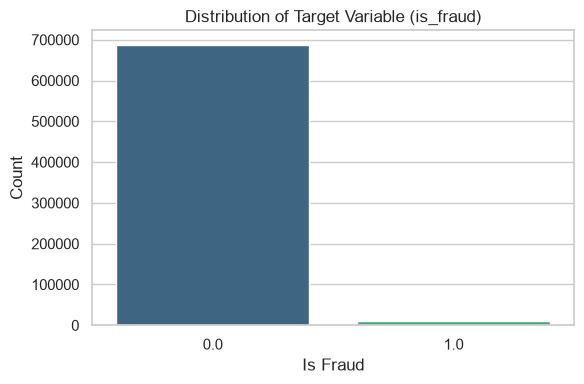

In [7]:
# 1. Target Variable Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='is_fraud', hue='is_fraud', palette='viridis', legend=False)
plt.title('Distribution of Target Variable (is_fraud)')
plt.xlabel('Is Fraud')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

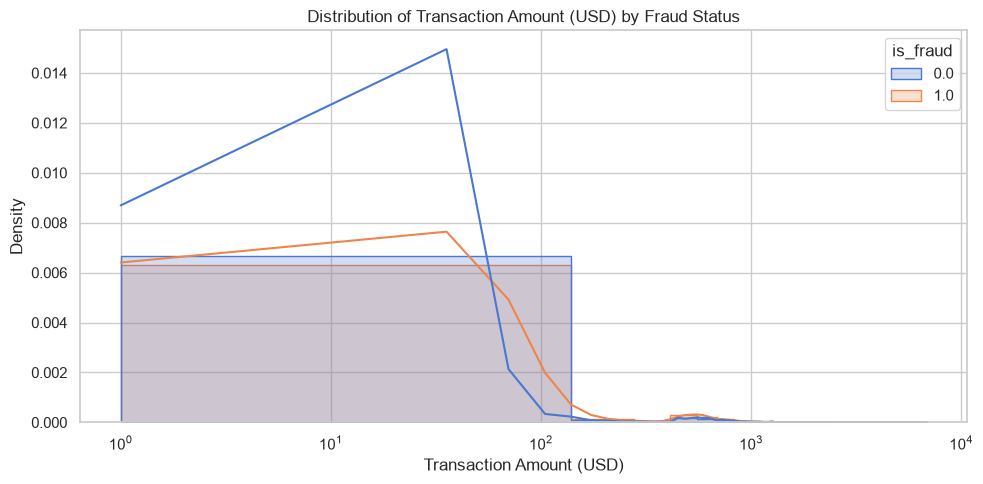

In [8]:
# 2. Transaction Amount Distribution (Log-scaled for readability)
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='amount_usd', hue='is_fraud', element='step', stat='density', common_norm=False, kde=True, palette='muted', bins=50)
plt.title('Distribution of Transaction Amount (USD) by Fraud Status')
plt.xlabel('Transaction Amount (USD)')
plt.ylabel('Density')
plt.xscale('log')
plt.tight_layout()
plt.show()

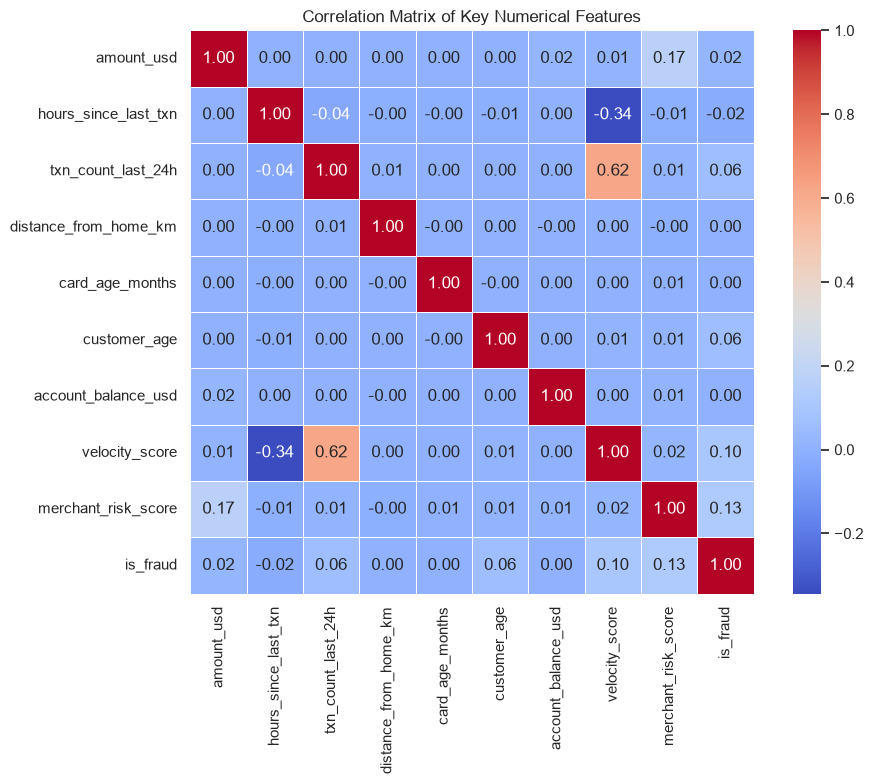

In [9]:
# 3. Correlation Matrix of Key Numeric Features
numeric_cols = [
    'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
    'distance_from_home_km', 'card_age_months', 'customer_age',
    'account_balance_usd', 'velocity_score', 'merchant_risk_score', 'is_fraud'
]
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Key Numerical Features')
plt.tight_layout()
plt.show()

C:\Users\MSI\AppData\Local\Temp\ipykernel_10996\205455455.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=df, x='channel', y='is_fraud', palette='Set2', errorbar=None)
C:\Users\MSI\AppData\Local\Temp\ipykernel_10996\205455455.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=df, x='auth_method', y='is_fraud', palette='Set2', errorbar=None)


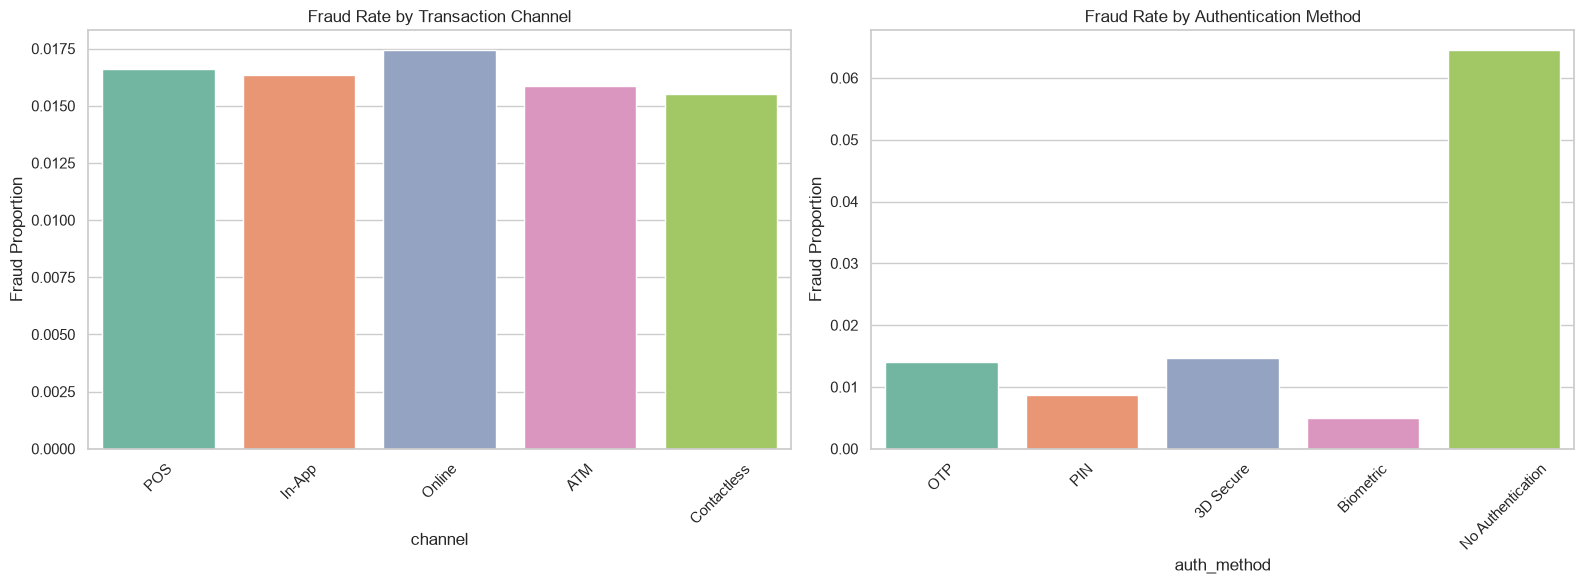

In [10]:
# 4. Fraud Rate by Channel & Authentication Method
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Channel vs Fraud Rate
sns.barplot(ax=axes[0], data=df, x='channel', y='is_fraud', palette='Set2', errorbar=None)
axes[0].set_title('Fraud Rate by Transaction Channel')
axes[0].set_ylabel('Fraud Proportion')
axes[0].tick_params(axis='x', rotation=45)

# Authentication Method vs Fraud Rate
sns.barplot(ax=axes[1], data=df, x='auth_method', y='is_fraud', palette='Set2', errorbar=None)
axes[1].set_title('Fraud Rate by Authentication Method')
axes[1].set_ylabel('Fraud Proportion')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Data cleaning

Remove duplicate rows and check the dataset for missing values.

In [11]:
df = df.drop_duplicates()

In [12]:
df.isnull().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

## Preprocessing and model preparation

Separate the target from the input features, split the data, and prepare numeric and categorical columns.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [14]:
x = df.drop(['is_fraud', 'id'],axis=1)
y = df['is_fraud']

In [15]:
# Drop rows containing NaNs in the specified columns
df = df.dropna(subset=['ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'is_fraud'])

# Redefine features and target with the cleaned data
x = df.drop(['is_fraud', 'id'], axis=1)
y = df['is_fraud']

# Verify that there are no NaNs left
print("Missing values in target:", y.isnull().sum())
print("Remaining shape of df:", df.shape)

Missing values in target: 0
Remaining shape of df: (699960, 26)


In [16]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Train shape:", x_train.shape)
print("Test shape:", x_test.shape)

Train shape: (559968, 24)
Test shape: (139992, 24)


In [17]:
numeric_cols = [
    'amount_usd',
    'hours_since_last_txn',
    'txn_count_last_24h',
    'distance_from_home_km',
    'card_age_months',
    'customer_age',
    'account_balance_usd',
    'cvv_retry_count',
    'velocity_score',
    'time_of_day_hour',
    'day_of_week',
    'merchant_risk_score',
    'prior_disputes',
    'is_foreign_transaction',
    'is_new_merchant',
    'used_vpn',
    'ip_country_mismatch',
    'billing_shipping_mismatch',
    'is_ai_generated_scam_attempt'
]

In [18]:
categorical_cols = [
    'merchant_category',
    'card_type',
    'auth_method',
    'channel',
    'device_type'
]

In [19]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ],
    remainder='drop'
)

## Logistic Regression baseline

Train a Logistic Regression pipeline and review its probability-based evaluation metrics.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

In [21]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42,max_iter=2000))
])

In [22]:
# Map boolean-like columns to integers (0 and 1)
bool_cols = ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

for col in bool_cols:
    x_train[col] = x_train[col].astype(str).str.strip().str.lower().map({'true': 1, 'false': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0})
    x_test[col] = x_test[col].astype(str).str.strip().str.lower().map({'true': 1, 'false': 0, '1': 1, '0': 0, '1.0': 1, '0.0': 0})


model.fit(x_train, y_train)

C:\Users\MSI\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['amount_usd',
                                                   'hours_since_last_txn',
                                                   'txn_count_last_24h',
                                                   'distance_from_home_km',
                                                   'card_age_months',
                                                   'customer_age',
                                                   'account_balance_usd',
                                                   'cvv_retry_count',
                                                   'velocity_score',
                                                   'time_of_day_hour',
                                                   'day_of_week',
                                                   'merchant_risk_score',
                                                   'prior_disputes',
                                                   'is_foreign_transaction',
                                                   'is_new_merchant',
                                                   'used_vpn',
                                                   'ip_country_mismatch',
                                                   'billing_shipping_mismatch',
                                                   'is_ai_generated_scam_attempt']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['merchant_category',
                                                   'card_type', 'auth_method',
                                                   'channel',
                                                   'device_type'])])),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])

In [23]:
y_pred = model.predict(x_test)

In [24]:
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, average_precision_score

# Predict probabilities instead of hard classes for AUC calculations
y_proba = model.predict_proba(x_test)[:, 1]

# 1. ROC-AUC Score
roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# 2. Precision-Recall AUC (PR-AUC)
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
pr_auc = auc(recall, precision)
print(f"Precision-Recall AUC (PR-AUC): {pr_auc:.4f}")

# 3. Average Precision (AP)
card_ap = average_precision_score(y_test, y_proba)
print(f"Average Precision Score: {card_ap:.4f}")

ROC-AUC Score: 0.9404
Precision-Recall AUC (PR-AUC): 0.4969
Average Precision Score: 0.4970


## XGBoost model and hyperparameter tuning

Train an XGBoost pipeline with class-weight adjustment, then search for parameters using average precision.

In [25]:
from xgboost import XGBClassifier

# Calculate the appropriate class ratio for scale_pos_weight
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
ratio = neg_count / pos_count
print(f"Negative-to-Positive Class Ratio: {ratio:.4f}")

# Create a pipeline with the preprocessor and the XGBoost model
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(scale_pos_weight=ratio, random_state=42, n_estimators=100, learning_rate=0.1, n_jobs=-1))
])

# Fit the pipeline on the training data
xgb_pipeline.fit(x_train, y_train)

Negative-to-Positive Class Ratio: 58.8832


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['amount_usd',
                                                   'hours_since_last_txn',
                                                   'txn_count_last_24h',
                                                   'distance_from_home_km',
                                                   'card_age_months',
                                                   'customer_age',
                                                   'account_balance_usd',
                                                   'cvv_retry_count',
                                                   'velocity_score',
                                                   'time_of_day_hour',
                                                   'day_of_week',
                                                   'merchant_risk_score',
                                                   'prior_disputes',
                                                   'is_foreign_transa...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [26]:
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc, average_precision_score

# Get predictions and probabilities for XGBoost
y_pred_xgb = xgb_pipeline.predict(x_test)
y_proba_xgb = xgb_pipeline.predict_proba(x_test)[:, 1]

# Calculate metrics for XGBoost
roc_auc_xgb = roc_auc_score(y_test, y_proba_xgb)
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_proba_xgb)
pr_auc_xgb = auc(recall_xgb, precision_xgb)
ap_xgb = average_precision_score(y_test, y_proba_xgb)

print("=== XGBoost Model Evaluation ===")
print(f"ROC-AUC Score: {roc_auc_xgb:.4f}")
print(f"Precision-Recall AUC (PR-AUC): {pr_auc_xgb:.4f}")
print(f"Average Precision Score: {ap_xgb:.4f}")

=== XGBoost Model Evaluation ===
ROC-AUC Score: 0.9406
Precision-Recall AUC (PR-AUC): 0.4860
Average Precision Score: 0.4861


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Define the parameter grid to search
param_dist = {
    'classifier__max_depth': [3, 5, 7, 9],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__subsample': [0.6, 0.8, 1.0],
    'classifier__colsample_bytree': [0.6, 0.8, 1.0],
    'classifier__n_estimators': [100, 200]
}

# Set up randomized search optimizing for average precision
random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_dist,
    n_iter=8,
    scoring='average_precision',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting Hyperparameter Tuning (optimized for PR-AUC/Average Precision)...")
random_search.fit(x_train, y_train)

# Extract the best model
best_xgb_pipeline = random_search.best_estimator_
print("\nBest Parameters Found:", random_search.best_params_)


Starting Hyperparameter Tuning (optimized for PR-AUC/Average Precision)...
Fitting 3 folds for each of 8 candidates, totalling 24 fits


In [ ]:
# Evaluate the tuned XGBoost model
y_proba_tuned = best_xgb_pipeline.predict_proba(x_test)[:, 1]

roc_auc_tuned = roc_auc_score(y_test, y_proba_tuned)
precision_tuned, recall_tuned, _ = precision_recall_curve(y_test, y_proba_tuned)
pr_auc_tuned = auc(recall_tuned, precision_tuned)
ap_tuned = average_precision_score(y_test, y_proba_tuned)

print("=== Tuned XGBoost Model Evaluation ===")
print(f"ROC-AUC Score: {roc_auc_tuned:.4f}")
print(f"Precision-Recall AUC (PR-AUC): {pr_auc_tuned:.4f}")
print(f"Average Precision Score: {ap_tuned:.4f}")


## Save trained models

Save both trained pipelines in the `models` folder so the Streamlit app can load them.

In [ ]:
import joblib

model_path = MODEL_DIR / 'logistic_regression_model.pkl'
joblib.dump(model, model_path)
print(f'Model successfully saved to {model_path}')

In [ ]:
import joblib

model_path = MODEL_DIR / 'xgboost_fraud_detection.pkl'
joblib.dump(best_xgb_pipeline, model_path)
print(f'Model successfully saved to {model_path}')